<a href="https://colab.research.google.com/github/marinammvl-bit/practica3_MO/blob/main/%D0%97%D0%B0%D0%B4%D0%B0%D0%BD%D0%B8%D0%B5_3_%D0%9C%D0%9E.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Практическое занятие №3
Дисциплина: Машинное обучение
Тема: Телеком-отток и стоимость жилья
Вариант: 2
ФИО: Брисюк Марина Эдуардовна
Группа: Б1123-38.03.05ба(1)

Часть А: Регрессия (California Housing)

   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  MedHouseVal  
0    -122.23        4.526  
1    -122.22        3.585  
2    -122.24        3.521  
3    -122.25        3.413  
4    -122.25        3.422  
(20640, 9)


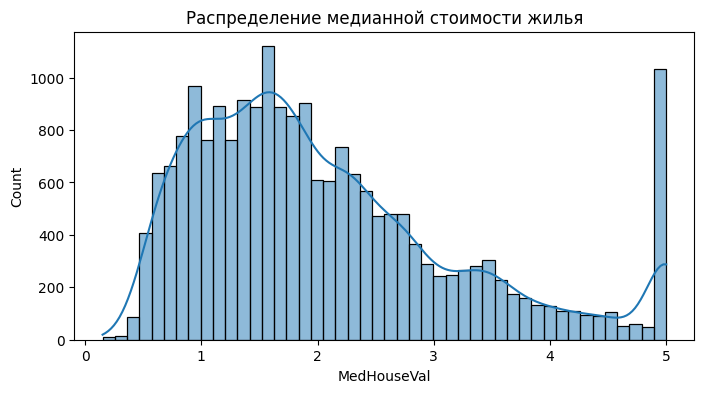

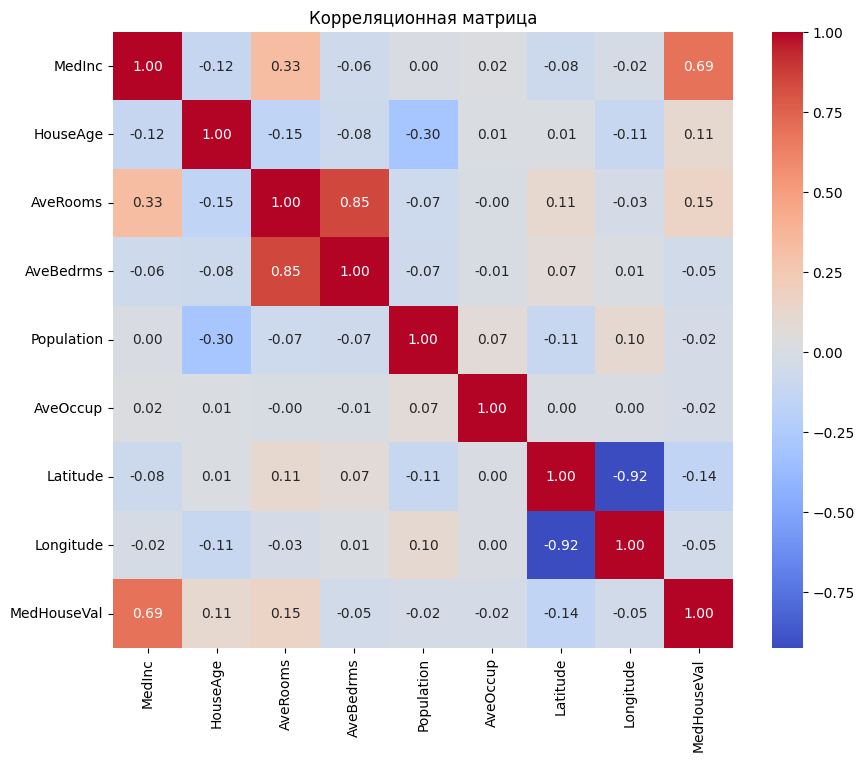

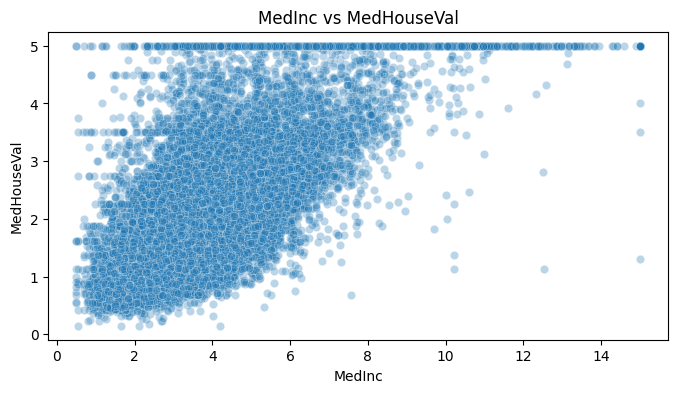

In [9]:
# Импорт необходимых библиотек
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Загрузка данных
housing = fetch_california_housing(as_frame=True)
df_reg = housing.frame
print(df_reg.head())
print(df_reg.shape)

# EDA (визуализация 1: распределение целевой переменной)
plt.figure(figsize=(8, 4))
sns.histplot(df_reg['MedHouseVal'], kde=True)
plt.title('Распределение медианной стоимости жилья')
plt.show()

# Визуализация 2: корреляционная матрица
plt.figure(figsize=(10, 8))
sns.heatmap(df_reg.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Корреляционная матрица')
plt.show()

# Визуализация 3: зависимость стоимости от медианного дохода
plt.figure(figsize=(8, 4))
sns.scatterplot(x='MedInc', y='MedHouseVal', data=df_reg, alpha=0.3)
plt.title('MedInc vs MedHouseVal')
plt.show()

In [10]:
# Признаки и целевая переменная
X_reg = df_reg.drop('MedHouseVal', axis=1)
y_reg = df_reg['MedHouseVal']

# Разделение 70/30
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg, y_reg, test_size=0.3, random_state=42
)

# Масштабирование
scaler_reg = StandardScaler()
X_train_reg_scaled = scaler_reg.fit_transform(X_train_reg)
X_test_reg_scaled = scaler_reg.transform(X_test_reg)

# Обучение LinearRegression
lr = LinearRegression()
lr.fit(X_train_reg_scaled, y_train_reg)

# Предсказание
y_pred_reg = lr.predict(X_test_reg_scaled)

# Метрики
rmse = np.sqrt(mean_squared_error(y_test_reg, y_pred_reg))
mae = mean_absolute_error(y_test_reg, y_pred_reg)
r2 = r2_score(y_test_reg, y_pred_reg)

print(f"RMSE: {rmse:.4f}")
print(f"MAE: {mae:.4f}")
print(f"R²: {r2:.4f}")

RMSE: 0.7284
MAE: 0.5272
R²: 0.5958


Модель показывает R² около 0.6, что означает объяснение примерно 60% дисперсии. RMSE около 0.73 (в единицах 100 000 долларов). Для бизнеса такой уровень может служить базовой оценкой, но для точной оценки конкретных объектов требуется учёт дополнительных факторов (состояние дома, инфраструктура).



Часть Б: (Telco Customer Churn)

In [11]:
df_churn = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')
print(df_churn.shape)
print(df_churn.head())

(7043, 21)
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMovies        Co

In [12]:
# Удаление customerID
df_churn = df_churn.drop('customerID', axis=1)

# Преобразование TotalCharges в числовой формат (пробелы становятся NaN)
df_churn['TotalCharges'] = pd.to_numeric(df_churn['TotalCharges'], errors='coerce')

# Заполнение пропусков (11 пропусков, обычно заполняют медианой или 0 для новых клиентов)
df_churn['TotalCharges'] = df_churn['TotalCharges'].fillna(df_churn['TotalCharges'].median())

# Кодирование целевой переменной
df_churn['Churn'] = df_churn['Churn'].map({'Yes': 1, 'No': 0})

# Разделение на признаки и целевую переменную
X_clf = df_churn.drop('Churn', axis=1)
y_clf = df_churn['Churn']

# Определение категориальных и числовых колонок
cat_cols = X_clf.select_dtypes(include=['object']).columns.tolist()
num_cols = X_clf.select_dtypes(include=['int64', 'float64']).columns.tolist()

# One-Hot Encoding для категориальных (drop_first=True для избежания мультиколлинеарности)
X_clf_encoded = pd.get_dummies(X_clf, columns=cat_cols, drop_first=True)

# Разделение train/test (стратификация по целевой переменной)
from sklearn.model_selection import train_test_split
X_train_clf, X_test_clf, y_train_clf, y_test_clf = train_test_split(
    X_clf_encoded, y_clf, test_size=0.3, random_state=42, stratify=y_clf
)

# Масштабирование числовых признаков
scaler_clf = StandardScaler()
# Масштабируем только исходные числовые колонки (после get_dummies они остались с теми же именами, кроме категориальных)
num_cols_present = [col for col in num_cols if col in X_train_clf.columns]
X_train_clf[num_cols_present] = scaler_clf.fit_transform(X_train_clf[num_cols_present])
X_test_clf[num_cols_present] = scaler_clf.transform(X_test_clf[num_cols_present])

print(f"Обучающая выборка: {X_train_clf.shape}")
print(f"Тестовая выборка: {X_test_clf.shape}")

Обучающая выборка: (4930, 30)
Тестовая выборка: (2113, 30)


Логистическая регрессия:
Accuracy: 0.8088
Precision: 0.6667
Recall: 0.5597
F1-score: 0.6085
ROC-AUC: 0.8447


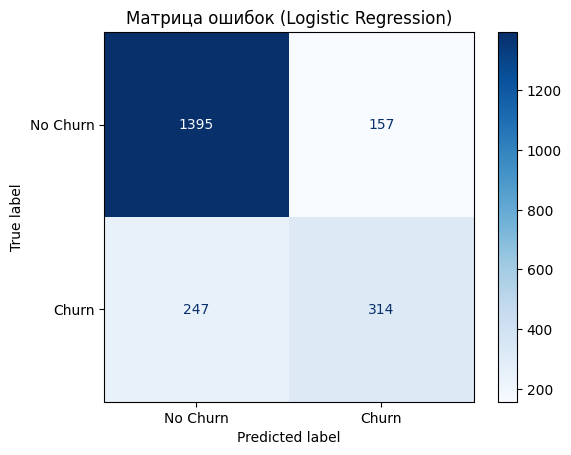

In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay

# Обучение
log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train_clf, y_train_clf)

# Предсказание
y_pred_log = log_reg.predict(X_test_clf)
y_proba_log = log_reg.predict_proba(X_test_clf)[:, 1]

# Метрики
print("Логистическая регрессия:")
print(f"Accuracy: {accuracy_score(y_test_clf, y_pred_log):.4f}")
print(f"Precision: {precision_score(y_test_clf, y_pred_log):.4f}")
print(f"Recall: {recall_score(y_test_clf, y_pred_log):.4f}")
print(f"F1-score: {f1_score(y_test_clf, y_pred_log):.4f}")
print(f"ROC-AUC: {roc_auc_score(y_test_clf, y_proba_log):.4f}")

# Матрица ошибок
cm = confusion_matrix(y_test_clf, y_pred_log)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Churn', 'Churn'])
disp.plot(cmap='Blues')
plt.title('Матрица ошибок (Logistic Regression)')
plt.show()

Для телеком-компании ложноотрицательные (FN, предсказали "не уйдёт", а клиент ушёл) обычно дороже, чем ложноположительные (FP, предсказали "уйдёт", предложили скидку, но клиент остался бы и так). Потеря клиента означает потерю будущей выручки, тогда как стоимость удержания (скидка) обычно ниже. Поэтому в бизнесе часто стремятся максимизировать Recall (полноту) для класса оттока, даже ценой некоторого снижения Precision.

Часть В: Деревья и ансамбли

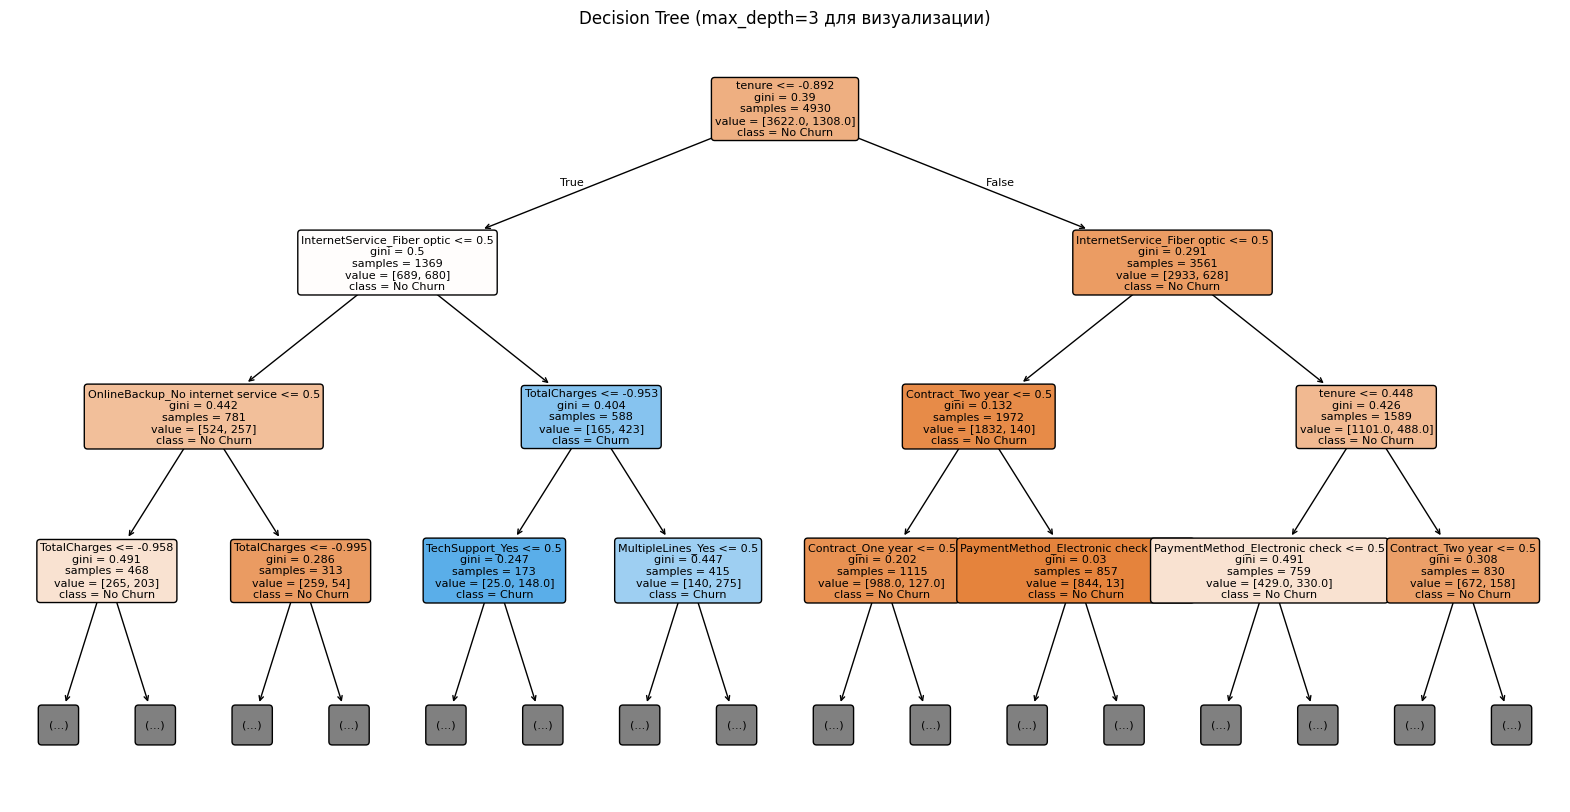

                 Model  Accuracy   ROC-AUC
0  Logistic Regression  0.808803  0.844716
1        Decision Tree  0.788452  0.820782
2        Random Forest  0.789872  0.819670
3    Gradient Boosting  0.796025  0.842009

Топ-5 важных признаков (Random Forest):
TotalCharges: 0.1861
tenure: 0.1718
MonthlyCharges: 0.1671
InternetService_Fiber optic: 0.0387
PaymentMethod_Electronic check: 0.0371


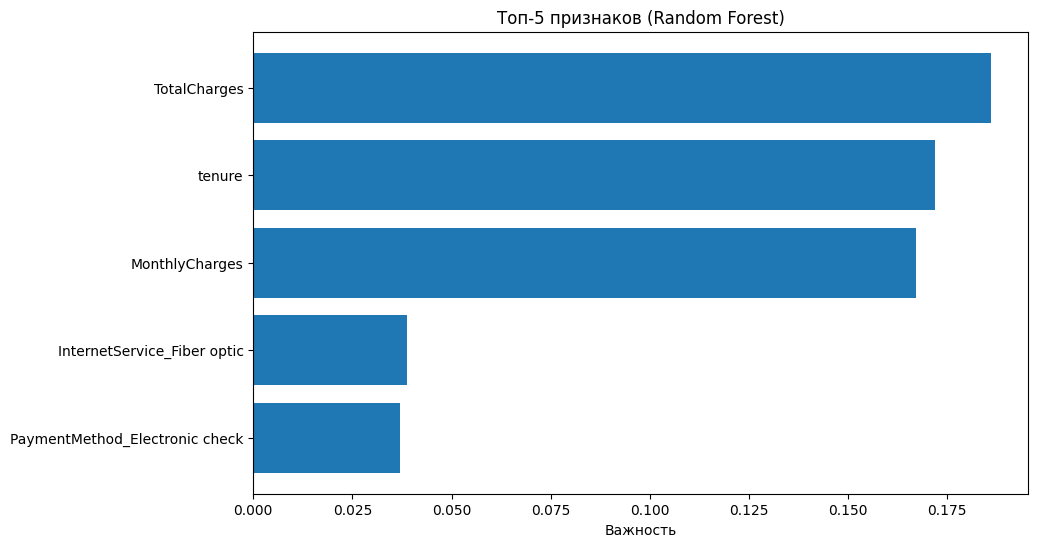

In [14]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

# 1. Decision Tree
dt = DecisionTreeClassifier(max_depth=5, random_state=42)
dt.fit(X_train_clf, y_train_clf)
y_pred_dt = dt.predict(X_test_clf)
y_proba_dt = dt.predict_proba(X_test_clf)[:, 1]

# 2. Random Forest
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train_clf, y_train_clf)
y_pred_rf = rf.predict(X_test_clf)
y_proba_rf = rf.predict_proba(X_test_clf)[:, 1]

# 3. Gradient Boosting
gb = GradientBoostingClassifier(n_estimators=100, random_state=42)
gb.fit(X_train_clf, y_train_clf)
y_pred_gb = gb.predict(X_test_clf)
y_proba_gb = gb.predict_proba(X_test_clf)[:, 1]

# 4. Визуализация дерева (первые 3 уровня)
plt.figure(figsize=(20, 10))
plot_tree(dt, max_depth=3, feature_names=X_train_clf.columns, class_names=['No Churn', 'Churn'], filled=True, rounded=True, fontsize=8)
plt.title('Decision Tree (max_depth=3 для визуализации)')
plt.show()

# 5. Сводная таблица
results = pd.DataFrame({
    'Model': ['Logistic Regression', 'Decision Tree', 'Random Forest', 'Gradient Boosting'],
    'Accuracy': [accuracy_score(y_test_clf, y_pred_log), accuracy_score(y_test_clf, y_pred_dt), accuracy_score(y_test_clf, y_pred_rf), accuracy_score(y_test_clf, y_pred_gb)],
    'ROC-AUC': [roc_auc_score(y_test_clf, y_proba_log), roc_auc_score(y_test_clf, y_proba_dt), roc_auc_score(y_test_clf, y_proba_rf), roc_auc_score(y_test_clf, y_proba_gb)]
})
print(results)

# 6. Топ-5 важных признаков по Random Forest
importances = rf.feature_importances_
indices = np.argsort(importances)[::-1][:5]
print("\nТоп-5 важных признаков (Random Forest):")
for i in indices:
    print(f"{X_train_clf.columns[i]}: {importances[i]:.4f}")

# Визуализация важности
plt.figure(figsize=(10, 6))
plt.barh([X_train_clf.columns[i] for i in indices], [importances[i] for i in indices])
plt.xlabel('Важность')
plt.title('Топ-5 признаков (Random Forest)')
plt.gca().invert_yaxis()
plt.show()

Рекомендация для внедрения: Random Forest или Gradient Boosting показывают более высокий ROC-AUC и Accuracy по сравнению с логистической регрессией и одиночным деревом. Однако логистическая регрессия обеспечивает наилучшую интерпретируемость коэффициентов. Для задачи удержания клиентов, где важно не только точно предсказывать отток, но и объяснять менеджерам причины, Random Forest является хорошим компромиссом: он даёт важность признаков и обычно превосходит логистическую регрессию по качеству. Если бизнес требует максимальной точности и готов пожертвовать прозрачностью, выбирается Gradient Boosting.